# 1. Basic borrow / lend
Model vs. contracts cross-check, then a 7-day pool under v0.7 (deployed) and v0.8 (2026-10-23 decisions) rules with the same random seed.

In [1]:
import csv
from pathlib import Path
OUT = Path("../out")

def load(name):
    """rows of out/<name>.csv as dicts (numbers stay strings; use f())"""
    with open(OUT / f"{name}.csv") as fh:
        return list(csv.DictReader(fh))

def f(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return x

def show(rows, cols=None, limit=40, where=None):
    """print rows as an aligned table"""
    if where:
        rows = [r for r in rows if where(r)]
    rows = rows[:limit]
    if not rows:
        print("(no rows)"); return
    cols = cols or list(rows[0].keys())
    def fmt(v):
        try:
            x = float(v)
            return f"{x:,.4g}" if abs(x) < 1e6 else f"{x:,.0f}"
        except (TypeError, ValueError):
            return str(v)
    cells = [[fmt(r.get(c, "")) for c in cols] for r in rows]
    w = [max(len(c), *(len(row[i]) for row in cells)) for i, c in enumerate(cols)]
    print(" | ".join(c.ljust(w[i]) for i, c in enumerate(cols)))
    print("-+-".join("-" * x for x in w))
    for row in cells:
        print(" | ".join(v.rjust(w[i]) for i, v in enumerate(row)))

def svg(name):
    """display a pre-rendered chart from out/plots"""
    p = OUT / "plots" / name
    try:
        from IPython.display import SVG, display
        display(SVG(filename=str(p)))
    except Exception:
        print(f"[chart: {p}]")

## Cross-check: Rust model against the compiled contracts in revm
Every random batch must agree on P*, filled units and every account's R / C / pending balances.

In [2]:
cc = load("crosscheck")
print("batches:", len(cc), " price mismatches:", sum(r["price_match"] != "true" for r in cc), " payout mismatches:", sum(r["payouts_match"] != "true" for r in cc))
gas = sorted(f(r["evm_settle_gas"]) for r in cc); print("settleBatch gas min/median/max:", gas[0], gas[len(gas)//2], gas[-1])

batches: 180  price mismatches: 0  payout mismatches: 0
settleBatch gas min/median/max: 59582.0 372913.0 788497.0


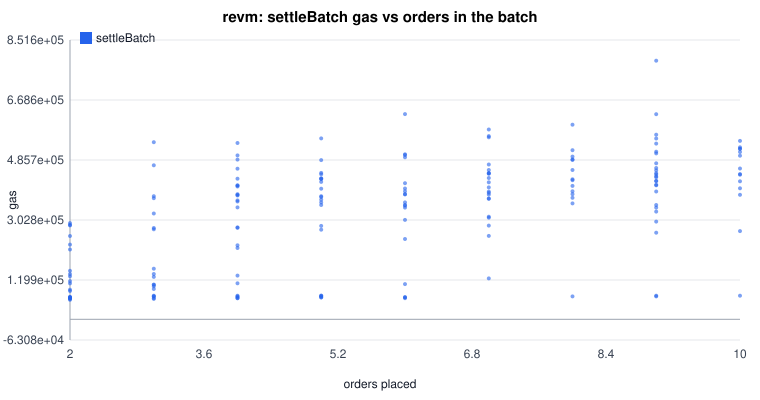

In [3]:
svg("crosscheck_gas.svg")  # settleBatch gas vs orders

## Baseline lifecycle

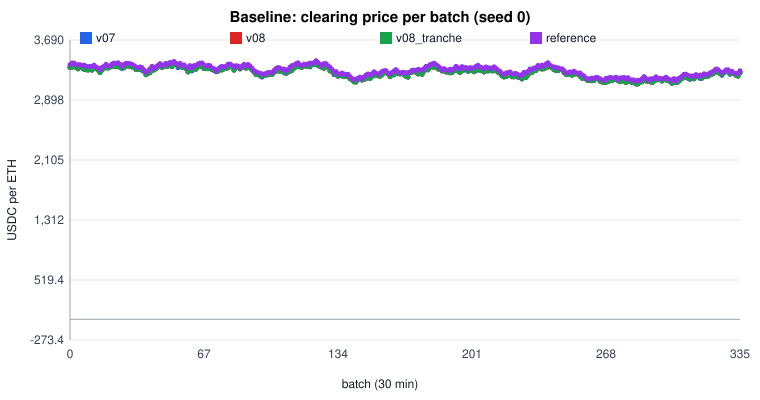

In [4]:
svg("baseline_price.svg")  # clearing price per batch, seed 0

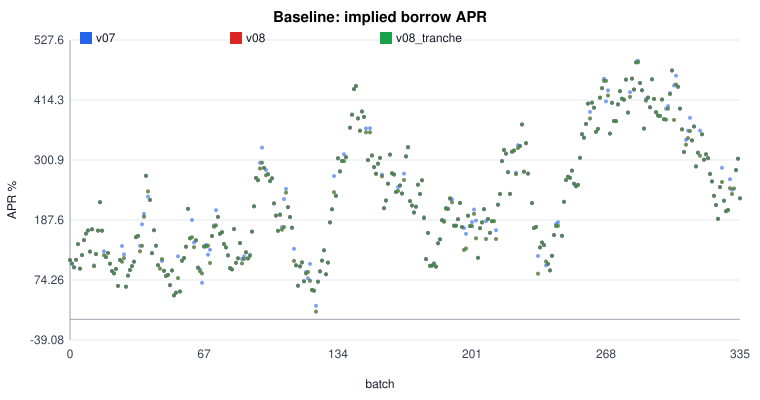

In [5]:
svg("baseline_apr.svg")  # implied borrow APR

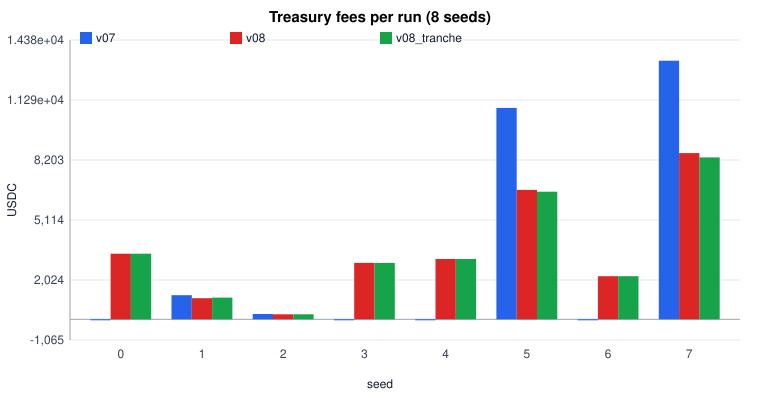

In [6]:
svg("baseline_treasury.svg")  # treasury fees per run

In [7]:
show(load("baseline_summary"), ["rules","seed","final_ref_price","total_units","default_ratio","treasury_fees","c_holder_quote","c_holder_asset","lender_return_on_quote_paid"])

rules       | seed | final_ref_price | total_units | default_ratio | treasury_fees | c_holder_quote | c_holder_asset | lender_return_on_quote_paid
------------+------+-----------------+-------------+---------------+---------------+----------------+----------------+----------------------------
        v07 |    0 |           3,285 |       3,430 |             1 |             0 |        2.1e-05 |          3,430 |                    0.008326
        v08 |    0 |           3,285 |       3,458 |             1 |         3,381 |      2.416e+04 |          3,458 |                     0.01006
v08_tranche |    0 |           3,285 |       3,458 |             1 |         3,381 |      2.416e+04 |          3,458 |                     0.01006
        v07 |    1 |           3,794 |       440.1 |        0.1193 |         1,240 |      1,316,465 |           52.5 |                     0.02262
        v08 |    1 |           3,794 |         453 |        0.1302 |         1,086 |      1,339,694 |             59 |

Under v0.7 a fully defaulted pool pays the treasury nothing; under v0.8 the 0.03 % trade fee was collected at clearing. When borrowers repay, v0.7's 10 % of interest exceeds v0.8's 5 % + 0.03 %.